In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import precision_score, recall_score

In [40]:
COLORS = ['#527DAA', '#D96B5F']

In [41]:
df = pd.read_csv('../data/raw/bs140513_032310.csv')

df = df.drop(columns=['zipcodeOri', 'zipMerchant'])
df['log_amount'] = np.log1p(df['amount'])

df['customer'] = df['customer'].str.strip("'")
df['merchant'] = df['merchant'].str.strip("'")
df['category'] = df['category'].str.strip("'")

# Разработка антифрод-правил

На этапе EDA мы обнаружили, что суммы мошеннических операций в среднем значительно выше обычных. Теперь попробуем использовать эту закономерность для выявления подозрительных транзакций.

## 1.1. Правило №1 — необычно крупная сумма транзакции

Для начала определим порог крупной суммы. В качестве ориентира используем 95-й перцентиль обычных транзакций (`fraud = 0`). Это позволит выделить операции, сумма которых превышает типичный диапазон большинства обычных платежей.

Важно: превышение порога ещё не означает мошенничество. Это только сигнал для дополнительной проверки.

In [42]:
threshold = df.loc[df['fraud'] == 0, 'amount'].quantile(0.95)
threshold

np.float64(72.81)

In [43]:
df['large_amount'] = df['amount'] > threshold

df['large_amount'].value_counts()

large_amount
False    558933
True      35710
Name: count, dtype: int64

In [44]:
pd.crosstab(
    df['large_amount'],
    df['fraud'],
    normalize='index'
).round(3) * 100

fraud,0,1
large_amount,,
False,99.8,0.2
True,82.2,17.8


In [45]:
precision = precision_score(df['fraud'], df['large_amount'])
recall = recall_score(df['fraud'], df['large_amount'])

print(f'Precision: {precision:.3f}')
print(f'Recall: {recall:.3f}')

Precision: 0.178
Recall: 0.881


### Оценка первого антифрод-правила

Порог в 72.81 позволил выделить транзакции с повышенным уровнем риска. Среди операций, превысивших этот порог, доля мошеннических составляет 17.8%, тогда как среди остальных — всего 0.2%.

Метрики эффективности правила:
- **Precision — 17.8%**: только такая доля отмеченных транзакций действительно оказалась мошеннической.
- **Recall — 88.1%**: правило выявило большую часть всех мошеннических операций.

Таким образом, крупная сумма — полезный сигнал для выявления мошенничества, но правило даёт много ложных срабатываний. Его лучше использовать в сочетании с другими критериями оценки риска.

## 1.2. Правило №2 — выявление нетипичных сумм для клиента

Крупная сумма не всегда является подозрительной: для одного клиента такая операция может быть привычной, а для другого — совершенно необычной.

Поэтому сравним сумму каждой транзакции со средней суммой операций соответствующего клиента. Если сумма значительно превышает его обычный уровень расходов, будем считать такую операцию подозрительной.

In [46]:
df['customer_avg_amount'] = df.groupby('customer')['amount'].transform('mean')

df['amount_to_customer_avg'] = (
    df['amount'] / df['customer_avg_amount']
)

df.groupby('fraud')['amount_to_customer_avg'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
fraud,,,,,,,,
0,587443.0,0.94,0.88,0.0,0.38,0.78,1.26,50.94
1,7200.0,6.12,9.45,0.0,1.02,2.89,7.69,94.38


Определим порог по 95-му перцентилю обычных транзакций — по аналогии с первым правилом.

In [47]:
customer_threshold = df.loc[
    df['fraud'] == 0, 'amount_to_customer_avg'
].quantile(0.95)

customer_threshold

np.float64(2.2003755583267957)

Подозрительными будем считать транзакции, сумма которых более чем в 2.2 раза превышает среднюю сумму операций клиента.

In [48]:
df['unusual_amount'] = (
    df['amount_to_customer_avg'] > customer_threshold
)

df['unusual_amount'].value_counts()

unusual_amount
False    561213
True      33430
Name: count, dtype: int64

In [49]:
pd.crosstab(
    df['unusual_amount'],
    df['fraud'],
    normalize='index'
).round(3) * 100

fraud,0,1
unusual_amount,,
False,99.4,0.6
True,87.9,12.1


In [50]:
precision = precision_score(df['fraud'], df['unusual_amount'])
recall = recall_score(df['fraud'], df['unusual_amount'])

print(f'Precision: {precision:.3f}')
print(f'Recall: {recall:.3f}')

Precision: 0.121
Recall: 0.563


### Оценка второго антифрод-правила

Правило выявления нетипичных сумм отметило 33 430 транзакций. Среди них мошенническими оказались 12.1%.

Метрики эффективности:
- **Precision — 12.1%**: доля мошеннических операций среди отмеченных правилом.
- **Recall — 56.3%**: правило выявило 56.3% всех мошеннических операций.

По сравнению с первым правилом результат хуже по обеим метрикам. Тем не менее отклонение от привычной суммы клиента может быть полезным дополнительным признаком при комплексной оценке риска.

## 1.3. Правило №3 — выявление частых операций клиента

Ещё один возможный признак мошенничества — большое количество транзакций от одного клиента за короткий промежуток времени.

В датасете `step` обозначает условный временной шаг. Посчитаем, сколько операций совершает каждый клиент на каждом шаге, и проверим, связана ли повышенная частота транзакций с мошенничеством.

Распределение количества операций:

In [51]:
df['customer_step_count'] = (
    df.groupby(['customer', 'step'])['amount'].transform('count')
)

df['customer_step_count'].value_counts().sort_index()

customer_step_count
1    551162
2     39386
3      3096
4       924
5        75
Name: count, dtype: int64

Проверим, насколько часто мошенничество встречается при разном количестве операций:

In [52]:
pd.crosstab(
    df['customer_step_count'],
    df['fraud'],
    normalize='index'
).round(3) * 100

fraud,0,1
customer_step_count,,
1,99.4,0.6
2,91.3,8.7
3,83.4,16.6
4,85.0,15.0
5,20.0,80.0


При двух и более операциях за один временной шаг доля мошенничества заметно выше, чем при одной операции. Особенно высокие значения наблюдаются при 3–5 транзакциях, однако для последних групп количество наблюдений небольшое. Поэтому частоту операций можно использовать как дополнительный признак риска, но не как самостоятельное доказательство мошенничества.

In [53]:
df['frequent_transactions'] = df['customer_step_count'] >= 2

df['frequent_transactions'].value_counts()

frequent_transactions
False    551162
True      43481
Name: count, dtype: int64

In [54]:
pd.crosstab(
    df['frequent_transactions'],
    df['fraud'],
    normalize='index'
).round(3) * 100

fraud,0,1
frequent_transactions,,
False,99.4,0.6
True,90.5,9.5


In [55]:
precision = precision_score(df['fraud'], df['frequent_transactions'])
recall = recall_score(df['fraud'], df['frequent_transactions'])

print(f'Precision: {precision:.3f}')
print(f'Recall: {recall:.3f}')

Precision: 0.095
Recall: 0.575


По сравнению с предыдущими правилами это самый низкий Precision. При этом Recall немного выше, чем у правила нетипичной суммы клиента.

Таким образом, частота операций может быть дополнительным сигналом риска, но самостоятельно правило работает недостаточно точно.

## 1.4. Общий риск-скоринг

Каждое из разработанных правил выявляет определённую особенность транзакции, но по отдельности они дают много ложных срабатываний.

Объединим три правила в общий риск-скоринг. За каждое сработавшее правило транзакция будет получать один балл. Итоговая оценка будет находиться в диапазоне от 0 до 3.

Чем выше балл, тем больше признаков подозрительной активности обнаружено.

In [56]:
rules = [
    'large_amount',
    'unusual_amount',
    'frequent_transactions'
]

df['risk_score'] = df[rules].sum(axis=1)

df['risk_score'].value_counts().sort_index()

risk_score
0    523454
1     39999
2     20948
3     10242
Name: count, dtype: int64

Смотрим, как меняется доля мошенничества в зависимости от риск-скора:

In [57]:
risk_stats = df.groupby('risk_score').agg(
    transactions=('fraud', 'count'),
    fraud_count=('fraud', 'sum'),
    fraud_rate=('fraud', 'mean')
)

risk_stats['fraud_rate'] *= 100

risk_stats.round(2)

,transactions,fraud_count,fraud_rate
risk_score,,,
0,523454,342,0.07
1,39999,1654,4.14
2,20948,2729,13.03
3,10242,2475,24.17


Рассмотрим, как меняется доля мошеннических операций в зависимости от значения Risk Score. Это позволит оценить, насколько хорошо риск-скоринг разделяет обычные и мошеннические транзакции.

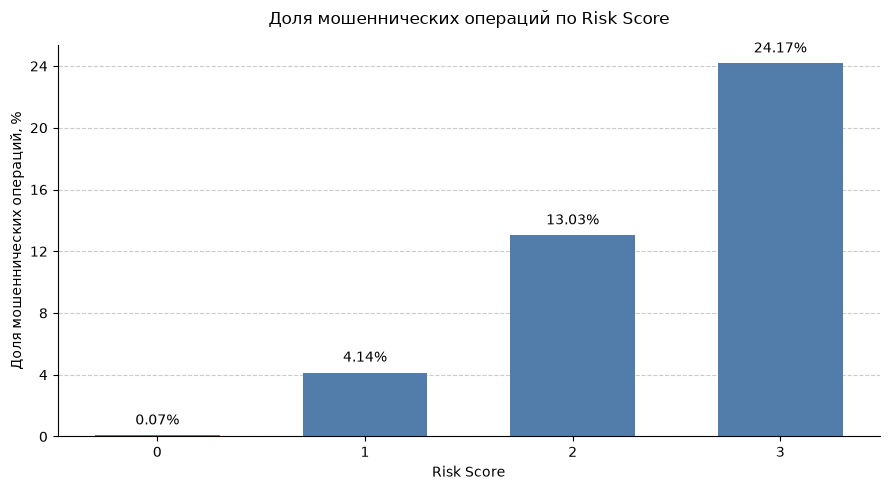

In [58]:
fig, ax = plt.subplots(figsize=(9, 5))

risk_rates = risk_stats['fraud_rate']

bars = ax.bar(
    risk_rates.index.astype(str),
    risk_rates.values,
    color=COLORS[0],
    width=0.6
)

ax.set_title('Доля мошеннических операций по Risk Score', pad=15)
ax.set_xlabel('Risk Score')
ax.set_ylabel('Доля мошеннических операций, %')

ax.yaxis.set_major_locator(plt.MaxNLocator(8))
ax.yaxis.grid(True, linestyle='--', linewidth=0.8, alpha=0.65)
ax.set_axisbelow(True)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f'{bar.get_height():.2f}%',
        ha='center',
        va='bottom',
        fontsize=10
    )

sns.despine()
plt.tight_layout()
plt.show()

### Результаты риск-скоринга

После объединения трёх правил обнаружилась закономерность: с увеличением риск-скора растёт доля мошеннических операций.

- При 0 баллов доля мошенничества составляет всего 0.07%.
- При 1 балле — 4.14%.
- При 2 баллах — 13.03%.
- При 3 баллах — 24.17%.

Таким образом, совместное использование нескольких признаков позволяет лучше разделять транзакции по уровню риска. Чем больше правил срабатывает одновременно, тем выше вероятность мошенничества.

Проверим три варианта порога:
- риск-скоринг от 1 балла;
- от 2 баллов;
- только 3 балла.

In [59]:
for threshold in [1, 2, 3]:
    prediction = df['risk_score'] >= threshold

    precision = precision_score(df['fraud'], prediction)
    recall = recall_score(df['fraud'], prediction)

    print(f'Порог: {threshold}')
    print(f'Precision: {precision:.3f}')
    print(f'Recall: {recall:.3f}')
    print()

Порог: 1
Precision: 0.096
Recall: 0.953

Порог: 2
Precision: 0.167
Recall: 0.723

Порог: 3
Precision: 0.242
Recall: 0.344



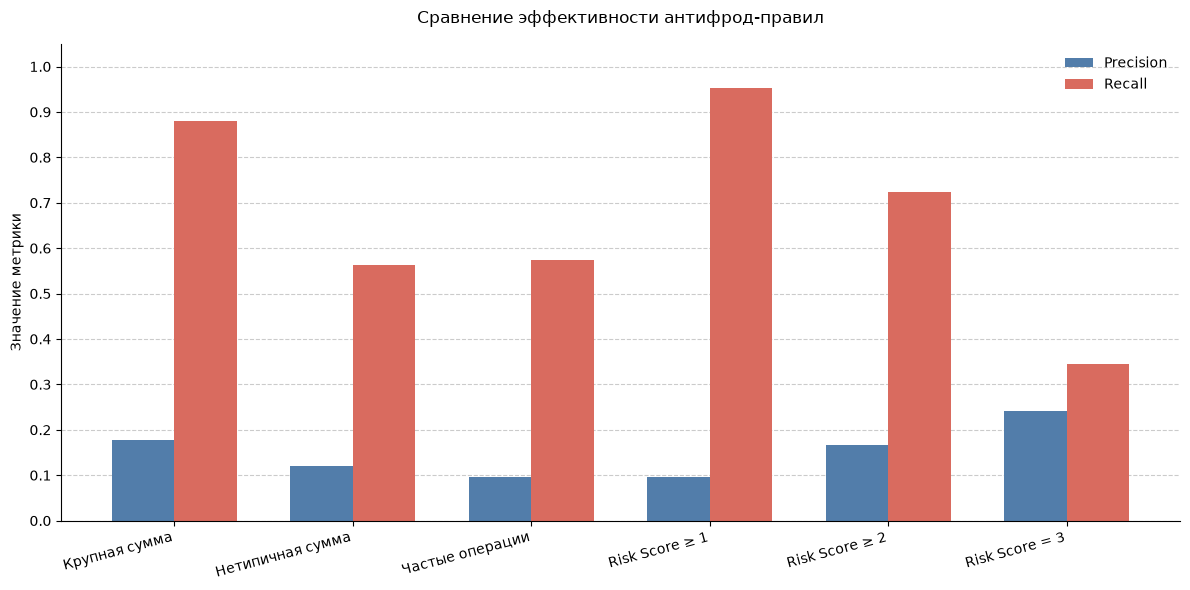

In [60]:
metrics = pd.DataFrame({
    'Правило': [
        'Крупная сумма',
        'Нетипичная сумма',
        'Частые операции',
        'Risk Score ≥ 1',
        'Risk Score ≥ 2',
        'Risk Score = 3'
    ],
    'Precision': [0.178, 0.121, 0.095, 0.096, 0.167, 0.242],
    'Recall': [0.881, 0.563, 0.575, 0.953, 0.723, 0.344]
})

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(metrics))
width = 0.35

ax.bar(x - width / 2, metrics['Precision'], width,
       label='Precision', color=COLORS[0])

ax.bar(x + width / 2, metrics['Recall'], width,
       label='Recall', color=COLORS[1])

ax.set_title('Сравнение эффективности антифрод-правил', pad=15)
ax.set_ylabel('Значение метрики')
ax.set_xticks(x)
ax.set_xticklabels(metrics['Правило'], rotation=15, ha='right')
ax.set_ylim(0, 1.05)

ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
ax.yaxis.grid(True, linestyle='--', linewidth=0.8, alpha=0.65)
ax.set_axisbelow(True)

ax.legend(frameon=False)
sns.despine()

plt.tight_layout()
plt.show()

### Оценка эффективности риск-скоринга

Проверили три порога риск-скора и получили следующие результаты:

- **От 1 балла:** Precision — 9.6%, Recall — 95.3%. Выявляется почти всё мошенничество, но количество ложных срабатываний очень большое.
- **От 2 баллов:** Precision — 16.7%, Recall — 72.3%. Более сбалансированный вариант между количеством выявленных мошеннических операций и точностью.
- **3 балла:** Precision — 24.2%, Recall — 34.4%. Точность выше, но правило пропускает большую часть мошеннических операций.

Таким образом, выбор порога зависит от задач мониторинга. Если важно не пропустить подозрительные операции, лучше использовать порог от 1 балла. Если необходимо сократить количество проверок, можно повысить порог до 2 или 3 баллов.

Важно: риск-скоринг пока не превзошёл первое правило по сочетанию Precision и Recall. Но он позволяет гибко управлять чувствительностью системы, меняя порог срабатывания.

## 1.5. Анализ подозрительных транзакций

### 1.5.1. Анализ отдельных транзакций

После построения риск-скоринга можно перейти от общей статистики к анализу отдельных операций.

Рассмотрим транзакции с максимальным риск-скором — 3 балла. Они одновременно соответствуют всем трём разработанным правилам.

Изучим их суммы, категории, торговые точки и активность клиентов. Это поможет понять, какие именно операции попадают в группу повышенного риска.

In [61]:
suspicious_transactions = df[df['risk_score'] == 3].copy()

suspicious_transactions[
    [
        'step', 'customer', 'merchant', 'category',
        'amount', 'customer_avg_amount',
        'amount_to_customer_avg', 'customer_step_count',
        'risk_score', 'fraud'
    ]
].sort_values('amount', ascending=False).head(20)

,step,customer,merchant,category,amount,customer_avg_amount,amount_to_customer_avg,customer_step_count,risk_score,fraud
513394,158,C702798720,M732195782,es_travel,8329.96,88.256579,94.383445,3,3,1
135692,48,C806399525,M732195782,es_travel,7665.56,353.398692,21.690969,2,3,1
383889,122,C1007572087,M732195782,es_travel,7635.41,108.278667,70.516291,2,3,1
329533,107,C430880678,M2080407379,es_travel,7403.44,81.292798,91.071291,2,3,1
227774,77,C1817318774,M732195782,es_travel,7272.41,411.608214,17.668282,2,3,1
494531,153,C68881864,M732195782,es_travel,6620.36,76.653293,86.367587,2,3,1
117093,42,C806399525,M732195782,es_travel,6532.45,353.398692,18.484647,3,3,1
370324,118,C1872660217,M732195782,es_travel,6260.89,66.512471,94.131069,2,3,1
394764,125,C1581709798,M732195782,es_travel,6197.13,69.706154,88.903628,2,3,1
55958,21,C1413774656,M732195782,es_travel,6161.03,70.310655,87.625837,2,3,1


По первым 20 транзакциям с максимальными суммами видно:
1. Все 20 операций оказались мошенническими (fraud = 1).
2. Все операции относятся к категории es_travel.
3. Чаще всего встречается торговая точка M732195782.
4. Суммы транзакций составляют примерно от 5 500 до 8 300 — это значительно выше средних расходов соответствующих клиентов.
5. В некоторых случаях сумма превышает среднюю сумму операций клиента в 90 раз и более.

Но это только 20 крупнейших операций, поэтому пока нельзя переносить эти наблюдения на все подозрительные транзакции.

### 1.5.2 Анализ категорий и торговых точек

Чтобы не ограничиваться только крупнейшими транзакциями, изучим всю группу операций с риск-скором 3.

Посмотрим, какие категории и торговые точки встречаются в этой группе чаще всего и какая доля операций в них оказалась мошеннической.

In [62]:
category_risk = suspicious_transactions.groupby('category').agg(
    transactions=('fraud', 'count'),
    fraud_count=('fraud', 'sum'),
    fraud_rate=('fraud', 'mean')
)

category_risk['fraud_rate'] *= 100
category_risk.sort_values('fraud_rate', ascending=False).round(2)

,transactions,fraud_count,fraud_rate
category,,,
es_hyper,70,70,100.00
es_leisure,178,178,100.00
es_otherservices,78,77,98.72
es_travel,320,313,97.81
es_barsandrestaurants,39,37,94.87
es_hotelservices,243,199,81.89
es_sportsandtoys,822,613,74.57
es_home,224,99,44.20
es_tech,304,69,22.70


In [63]:
merchant_risk = suspicious_transactions.groupby('merchant').agg(
    transactions=('fraud', 'count'),
    fraud_count=('fraud', 'sum'),
    fraud_rate=('fraud', 'mean')
)

merchant_risk['fraud_rate'] *= 100
merchant_risk.sort_values('fraud_rate', ascending=False).head(15).round(2)

,transactions,fraud_count,fraud_rate
merchant,,,
M1294758098,66,66,100.00
M1353266412,24,24,100.00
M855959430,70,70,100.00
M3697346,112,112,100.00
M1873032707,84,84,100.00
M732195782,286,283,98.95
M1888755466,78,77,98.72
M2011752106,60,59,98.33
M980657600,452,444,98.23


### Выводы по категориям и торговым точкам

Есть несколько важных наблюдений.
1. По категориям
- es_health — количество мошеннических операций 586. Но доля мошенничества составляет 10.46%.
- es_sportsandtoys — 613 мошеннических операций при доле 74.57%.
- es_travel — 313 мошеннических операций, доля 97.81%.
- es_leisure и es_hyper — 100% мошеннических операций, но выборки значительно меньше.
2. По торговым точкам
- M980657600 — 444 мошеннические операции из 452 (98.23%).
- M732195782 — 283 из 286 (98.95%).
- У нескольких других продавцов все операции в этой группе оказались мошенническими.

Особенно интересно, что некоторые торговые точки сохраняют очень высокую долю мошенничества даже при относительно большом количестве операций.

Таким образом, категория и торговая точка могут быть полезными дополнительными признаками при расследовании подозрительных операций. Но при оценке результатов важно учитывать размер выборки: высокая доля мошенничества при небольшом количестве транзакций не всегда означает устойчивую закономерность.

### 1.5.3 Анализ подозрительных операций по клиентам

Проверим, концентрируются ли подозрительные операции у отдельных клиентов.

Для каждого клиента рассчитаем количество транзакций с максимальным риск-скором, количество мошеннических операций и долю мошенничества. Это поможет выявить клиентов с наиболее выраженной подозрительной активностью.

In [64]:
customer_risk = suspicious_transactions.groupby('customer').agg(
    transactions=('fraud', 'count'),
    fraud_count=('fraud', 'sum'),
    fraud_rate=('fraud', 'mean')
)

customer_risk['fraud_rate'] *= 100

customer_risk.sort_values(
    'fraud_count', ascending=False
).head(15).round(2)

,transactions,fraud_count,fraud_rate
customer,,,
C1275518867,31,31,100.00
C1978250683,29,29,100.00
C806399525,17,17,100.00
C218446443,17,17,100.00
C1647495093,16,16,100.00
C515668508,15,15,100.00
C1350963410,11,11,100.00
C587299231,11,11,100.00
C1383269171,12,10,83.33


### Выводы по анализу клиентов

Обнаружилась довольно сильная закономерность: у ряда клиентов все транзакции с максимальным риск-скором оказались мошенническими.

Что интересно:
- У первых восьми клиентов доля мошенничества составляет 100%.
- У C1275518867 обнаружена 31 мошенническая операция с максимальным риск-скором.
- У C1978250683 — 29 таких операций.
- У C806399525 — 17 операций. Этот клиент уже встречался среди крупнейших подозрительных транзакций.

Получается, анализ клиентской активности помогает выявлять повторяющиеся подозрительные операции и находить клиентов, требующих дополнительного внимания.

### 1.5.4. Разбор отдельных подозрительных случаев

Для более детального анализа выберем несколько транзакций с максимальным Risk Score. Рассмотрим, какие признаки вызвали подозрение, изучим другие операции соответствующих клиентов и оценим обоснованность срабатывания антифрод-правил.

In [65]:
selected_cases = []
selected_customers = set()

for column in ['amount', 'amount_to_customer_avg', 'customer_step_count']:
    candidates = suspicious_transactions.sort_values(column, ascending=False)

    for _, row in candidates.iterrows():
        if row['customer'] not in selected_customers:
            selected_cases.append(row)
            selected_customers.add(row['customer'])
            break

cases = pd.DataFrame(selected_cases)

cases[
    [
        'step', 'customer', 'merchant', 'category',
        'amount', 'customer_avg_amount',
        'amount_to_customer_avg', 'customer_step_count',
        'risk_score', 'fraud'
    ]
].round(2)

,step,customer,merchant,category,amount,customer_avg_amount,amount_to_customer_avg,customer_step_count,risk_score,fraud
513394,158,C702798720,M732195782,es_travel,8329.96,88.26,94.38,3,3,1
370324,118,C1872660217,M732195782,es_travel,6260.89,66.51,94.13,2,3,1
534397,163,C997029022,M480139044,es_health,261.35,38.62,6.77,5,3,1


Теперь рассмотрим каждого клиента отдельно:

In [66]:
customer_id = 'C702798720'

customer_history = df[df['customer'] == customer_id].sort_values('step')

customer_history[
    ['step', 'amount', 'category', 'fraud']
].round(2)

,step,amount,category,fraud
4469,1,60.26,es_wellnessandbeauty,0
37528,14,18.22,es_wellnessandbeauty,0
37529,14,42.47,es_wellnessandbeauty,0
67475,25,6.18,es_barsandrestaurants,0
71004,26,419.78,es_leisure,1
...,...,...,...,...
577125,175,34.51,es_transportation,0
583176,176,48.83,es_transportation,0
584207,177,12.10,es_transportation,0
589457,178,38.23,es_transportation,0


In [67]:
customer_history['amount'].describe().round(2)

count     152.00
mean       88.26
std       674.22
min         0.06
25%        14.40
50%        27.04
75%        42.18
max      8329.96
Name: amount, dtype: float64

Среднее значение заметно выше медианы из-за влияния крупных операций. При этом медиана и 75-й перцентиль показывают, что основная часть расходов клиента значительно ниже суммы подозрительной транзакции.

Проверим все мошеннические операции этого клиента:

In [68]:
customer_history[customer_history['fraud'] == 1][
    ['step', 'amount', 'category', 'merchant']
].sort_values('amount', ascending=False)

,step,amount,category,merchant
513394,158,8329.96,es_travel,M732195782
71004,26,419.78,es_leisure,M3697346


Этот случай показывает, что даже у клиента с преимущественно обычной активностью могут возникать отдельные крайне нетипичные операции. При этом мошеннические транзакции могут отличаться не только суммой, но и категорией расходов и торговой точкой.

In [69]:
customer_id = 'C1872660217'

customer_history = df[df['customer'] == customer_id].sort_values('step')

customer_history[
    ['step', 'amount', 'category', 'fraud']
].round(2)

,step,amount,category,fraud
1577,0,51.10,es_fashion,0
4726,1,11.21,es_transportation,0
5098,2,36.01,es_transportation,0
7819,3,93.34,es_food,0
10986,4,33.39,es_transportation,0
...,...,...,...,...
577565,175,20.62,es_transportation,0
581827,176,86.76,es_transportation,0
586385,177,7.01,es_transportation,0
587797,178,17.26,es_fashion,0


In [70]:
customer_history['amount'].describe().round(2)

count     174.00
mean       66.51
std       473.01
min         0.37
25%        13.71
50%        27.89
75%        38.20
max      6260.89
Name: amount, dtype: float64

In [71]:
customer_history[customer_history['fraud'] == 1][
    ['step', 'amount', 'category', 'merchant']
].sort_values('amount', ascending=False)

,step,amount,category,merchant
370324,118,6260.89,es_travel,M732195782


В этом случае подозрение связано с резким отклонением от привычного уровня расходов клиента. Дополнительное внимание привлекает совпадение торговой точки с одним из предыдущих расследуемых случаев. Это показывает, что анализ продавцов может дополнять индивидуальный анализ поведения клиента.

In [72]:
customer_id = 'C997029022'

customer_history = df[df['customer'] == customer_id].sort_values('step')

customer_history[
    ['step', 'amount', 'category', 'fraud']
].round(2)

,step,amount,category,fraud
2453,1,57.22,es_transportation,0
6967,2,34.88,es_transportation,0
10781,4,33.73,es_transportation,0
13126,5,29.27,es_transportation,0
16742,6,74.94,es_transportation,0
...,...,...,...,...
574732,174,33.10,es_transportation,0
580119,176,17.11,es_transportation,0
585898,177,40.02,es_hyper,0
588597,178,27.99,es_transportation,0


In [73]:
customer_history['amount'].describe().round(2)

count     92.00
mean      38.62
std       48.92
min        0.12
25%       13.38
50%       27.01
75%       40.86
max      319.29
Name: amount, dtype: float64

In [74]:
customer_history[customer_history['fraud'] == 1][
    ['step', 'amount', 'category', 'merchant']
].sort_values('amount', ascending=False)

,step,amount,category,merchant
534397,163,261.35,es_health,M480139044


In [75]:
df[df['customer'] == 'C997029022']['fraud'].sum()

np.int64(1)

Этот случай показывает, что мошенническая операция не обязательно должна иметь экстремально высокую сумму. Даже относительно небольшое отклонение от привычного поведения клиента может быть полезным сигналом для антифрод-системы. Поэтому при оценке риска важно учитывать не только абсолютную сумму, но и индивидуальные особенности расходов клиента.

### 1.5.5. Объяснение срабатывания антифрод-правил

Рассмотрим, какие именно признаки привели к присвоению максимального риск-скора выбранным транзакциям.

In [76]:
case_rules = cases[
    ['step', 'customer', 'amount', 'amount_to_customer_avg',
     'customer_step_count', 'large_amount',
     'unusual_amount', 'frequent_transactions', 'risk_score', 'fraud']
].copy()

case_rules

,step,customer,amount,amount_to_customer_avg,customer_step_count,large_amount,unusual_amount,frequent_transactions,risk_score,fraud
513394,158,C702798720,8329.96,94.383445,3,True,True,True,3,1
370324,118,C1872660217,6260.89,94.131069,2,True,True,True,3,1
534397,163,C997029022,261.35,6.766533,5,True,True,True,3,1


Здесь видно, что все три операции получили максимальный риск-скор не из-за одного признака, а из-за одновременного срабатывания всех трёх правил.

Первые два случая характеризуются аномально крупными суммами, значительно превышающими обычный уровень расходов клиентов. В третьем случае сумма меньше, но также заметно отклоняется от индивидуального уровня расходов, а повышенная частота операций усиливает подозрение.

Таким образом, сочетание нескольких независимых признаков позволяет выявлять не только экстремально крупные транзакции, но и менее очевидные отклонения от привычного поведения клиентов.

### Оценка обоснованности подозрений

Все три рассмотренные операции получили максимальный риск-скор и впоследствии подтвердились как мошеннические согласно целевой разметке датасета.

Это показывает, что выбранные правила смогли выявить реальные мошеннические операции в рассмотренных примерах. При этом результат нельзя распространять на все транзакции: для оценки надёжности системы необходимо учитывать также ложные срабатывания и пропущенные мошеннические операции.

В нашем датасете все три операции имеют метку fraud = 1, но в реальном банке такой результат был бы основанием для дополнительной проверки, а не автоматическим доказательством мошенничества.

## 1.6. Ограничения разработанных правил

Несмотря на выявленные закономерности, у разработанной системы есть несколько ограничений:

- Правило крупных сумм даёт высокий Recall, но при этом отмечает много обычных операций.
- Остальные правила по отдельности показывают сравнительно низкие Precision и Recall.
- Риск-скоринг улучшает гибкость системы, но не устраняет ложные срабатывания.
- Пороговые значения выбраны на основе этого же датасета. Для проверки их устойчивости потребуется отдельная валидация.
- Датасет синтетический, поэтому обнаруженные закономерности не обязательно будут повторяться на реальных банковских транзакциях.
- Средняя сумма операций клиента рассчитана по всей доступной истории, включая будущие относительно проверяемой транзакции операции. Для реального мониторинга необходимо рассчитывать этот показатель только по предыдущим транзакциям клиента.

Таким образом, разработанные правила подходят для первичного выявления подозрительных операций, но требуют дальнейшей проверки и доработки.

# Рекомендации для банка

По результатам анализа можно предложить следующие направления совершенствования мониторинга подозрительных операций:

1. **Использовать комплексную оценку риска.** Не ограничиваться проверкой суммы транзакции, а учитывать её отклонение от привычного поведения клиента и частоту операций.

2. **Настроить несколько уровней реагирования.** Операции с одним признаком риска направлять на дополнительный автоматизированный контроль, а с несколькими признаками — в приоритетную очередь аналитиков.

3. **Учитывать индивидуальный профиль клиента.** Оценивать транзакции относительно его обычных расходов, категорий покупок и частоты операций, а не только по общим пороговым значениям.

4. **Анализировать торговые точки и категории операций.** Учитывать повышенную концентрацию мошеннических транзакций у отдельных продавцов и в определённых категориях как дополнительный фактор риска.

5. **Регулярно пересматривать правила.** Контролировать Precision и Recall, анализировать ложные срабатывания и пропущенное мошенничество, корректировать пороги по мере изменения характера операций.

6. **Не считать срабатывание правила доказательством мошенничества.** Использовать риск-скор для определения приоритета проверки, а окончательное решение принимать после дополнительного анализа операции.

# Общие выводы

В ходе работы были разработаны и проверены три антифрод-правила: выявление крупных сумм, нетипичных расходов клиента и частых операций.

Затем правила были объединены в риск-скоринг, позволяющий оценивать транзакции по количеству обнаруженных подозрительных признаков.

Основные результаты:
- Наиболее эффективным отдельным правилом оказалось выявление крупных сумм (Precision — 17.8%, Recall — 88.1%).
- При пороге риск-скора от 1 балла удалось выявить 95.3% мошеннических операций.
- При повышении порога до 3 баллов Precision увеличился до 24.2%, но Recall снизился до 34.4%.
- Анализ подозрительных транзакций позволил выявить категории, торговые точки и клиентов с высокой концентрацией мошеннических операций.
- Отдельный анализ подозрительных операций помог выявить повторяющиеся закономерности, связанные с поведением клиентов, категориями покупок и торговыми точками. Это подтверждает важность анализа не только самой транзакции, но и контекста, в котором она совершена.

**Главный результат проекта** — реализация базового подхода к автоматизированному выявлению подозрительных операций и формированию приоритетов для дальнейшей проверки аналитиками.

При этом разработанная система является экспериментальной. Для практического применения потребуется проверка на реальных банковских данных, использование временной истории операций без утечки информации из будущего и дальнейшая настройка правил с учётом допустимого количества ложных срабатываний.

Разработанная система может использоваться как основа для первичного мониторинга транзакций. Для повышения качества выявления мошенничества в дальнейшем можно рассмотреть дополнительные признаки и методы машинного обучения.